# Chapter 4: Logistic Regression

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

In [2]:
import warnings
warnings.filterwarnings('ignore')

## 4.1 Introduction & Motivation

We've seen what linear regression can do, and we've seen the power of polynomial regression. Now with Logistic regression we are starting to dip out toes in the wonderful world of classification. Instead of trying to predict a number we are now trying to predict a **label**.

## 4.2 Problem Setting

Today we will be working with the Pima Indians Diabetics dataset. In this dataset is information regarding a whole bunch of women older than 21 years old of Pima Indian origin. The goal is to try and predict which women have **diabetes** and which do not. This is represented by the 'Outcome' column, where 1 means the person has diabetes and 0 means she does not.

## 4.3 Model

First, let's have a look at the data.

In [2]:
df = pd.read_csv("Diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [4]:
df.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [5]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


##### Question 1: Explore the data by creating a heatmap. Which variables would you use when trying to predict diabetes and why?

<Axes: >

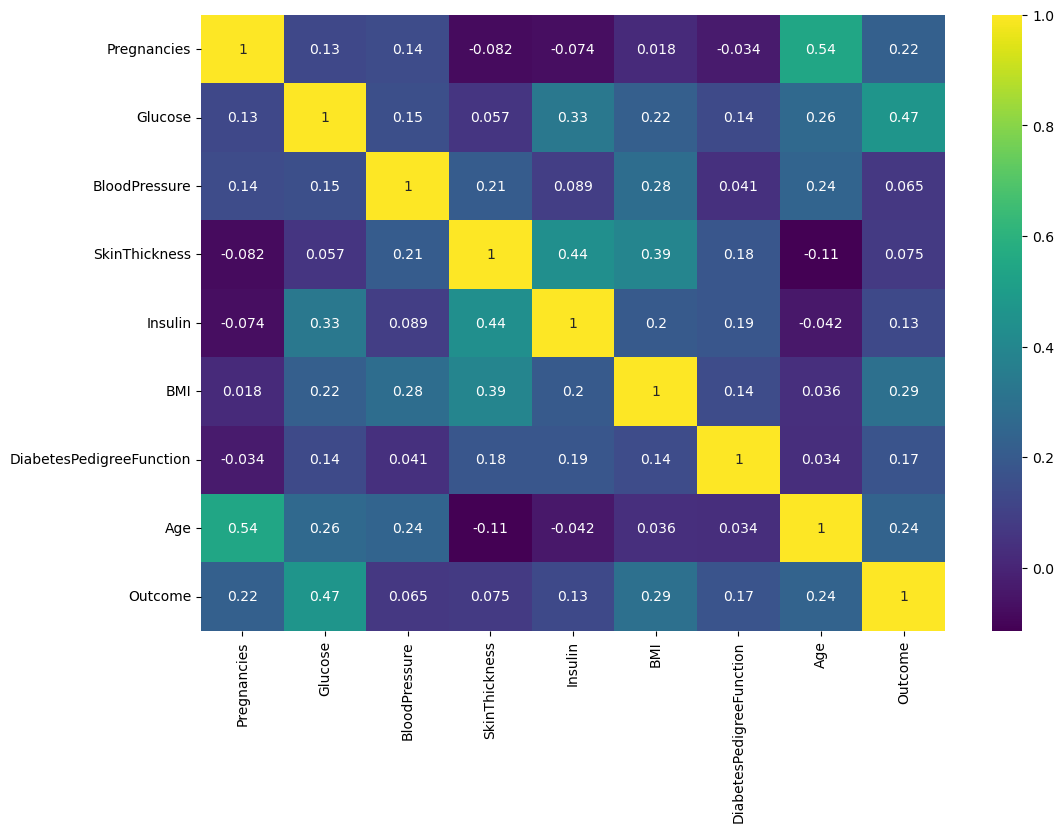

In [3]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap='viridis')

The variables that would be interesting to predict whether or not the person has diabetes are:

1. Glucose
2. BMI
3. Age
4. Pregancies
5. Age

##### Question 2: Create a train and test split of the data. Keep 30% of your data as testing data. Build your model using only the best parameter as found in question 1. For now, you can leave the solver at the default setting and keep the max_iter at 10000.

In [4]:
data = df[["Glucose"]]
booldata = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(data, booldata, test_size=0.3, random_state=101)

In [5]:
GlucoseModel = LogisticRegression(max_iter=10000)
GlucoseModel.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

##### Question 3: A person has a glucose level of 125. Predict if this person has diabetes or not.

In [6]:
Prediction = GlucoseModel.predict([[125]])
if(Prediction[0] == 0):
    print("No diabetes")
else:
    print("Diabetes detected")

No diabetes


c:\Users\jamey\Anaconda\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## 4.4 Model Evaluation

We have made our first prediction, but of course we don't know how well we can trust this yet. To know this, we first need to evaluate our model.

##### Question 4: Calculate all known classification metrics for your model. Are these values any good? Elaborate based on the formulas and meaning of the metrics.

##### 4.1. Accuracy Score

In [11]:
accuracy = GlucoseModel.score(X_test, y_test)
print(accuracy)

0.7532467532467533


##### 4.2. Precision Score

In [9]:
mypred = GlucoseModel.predict(X_test)
Precision = precision_score(y_test, mypred, average="weighted")
print(Precision) # Around 75% of datapoints labled as "positive" were correct. The other 25% labled as possitive where not. So 3 in 4 positivly labled datapoints were actually TP, the others where false positives.

0.749605143459892


##### 4.3. Specifity Score

In [30]:
SS = specificity_score(y_test, mypred, average="weighted")
print(SS)

0.6225557158890492


##### 4.4. Recall Score

In [ ]:
RecallScore = recall_score(y_test, mypred, average="weighted")
print(RecallScore) # There is about a 75% we tell you you are diabetic when you actually are. There is about a 25% we tell you you're not when you still actually are.

0.7532467532467533


##### 4.5. F1 score

In [28]:
F1score = f1_score(y_test, mypred, average="weighted")
print(F1score)

0.7372202265819287


### 4.6. Evaluation

Overall, the model presents a good baseline for predicting diabetes diagnosis: about 3 in 4 positive cases are correctly identified as positive, while 1 in 4 remain false negatives.
The model therefore isn't optimal, since the recall score for medical diagnosis is on the lower side. A better recall score would be around 90%.

##### Question 5: Based on your findings, is this model any good? Would you prefer a high recall or specificity in this use case? Why?

To answer question 5, let's take a look at the facts
1. Recall (75%) => Of all actual diabetics, 3 in 4 are correctly labled as "diabetic".
2. Precision (75%) => Of all predicted diabetics, 3 in 4 actually were diabetic.
3. Specificity (62%) => Of all those who are NOT diabetic, where about 62% correctly labled as "not diabetic"

The model all-in-all isn't bad, but it's not great either especially in a medical context. Specifically the Recall score needs to be higher as 1 in 4 actual diabetics are labled incorrectly as "healthy" (which could pose massive health risks). The aim is to increase the recall score to around 85 to 90%.
The specificity score is notably lower than all the other metrics. This is less important as it simply means that there will be more false positives, which is a lot less dangerous than false negatives.

##### Question 6: Plot the confuson matrix. How can you visually confirm your previous findings?

The findings are confirmed by the accuracy score being around 75%.

Furthermore, most patients are correctly labled as "not diabetic" with around a 25% margin of error. 
The amount of false positives appear to be lower than the amount of false negatives, which seem to contradict our previous findings since the recall score was higher than the specificity score (indicating more false positives than false negatives). However, this is still correct in proportion to the total amount. The amount of true negatives far outweighs the amount of true positives, meaning that overall: negative cases are detected more accuratly than positive cases.

Text(0.5, 58.7222222222222, 'Predicted label')

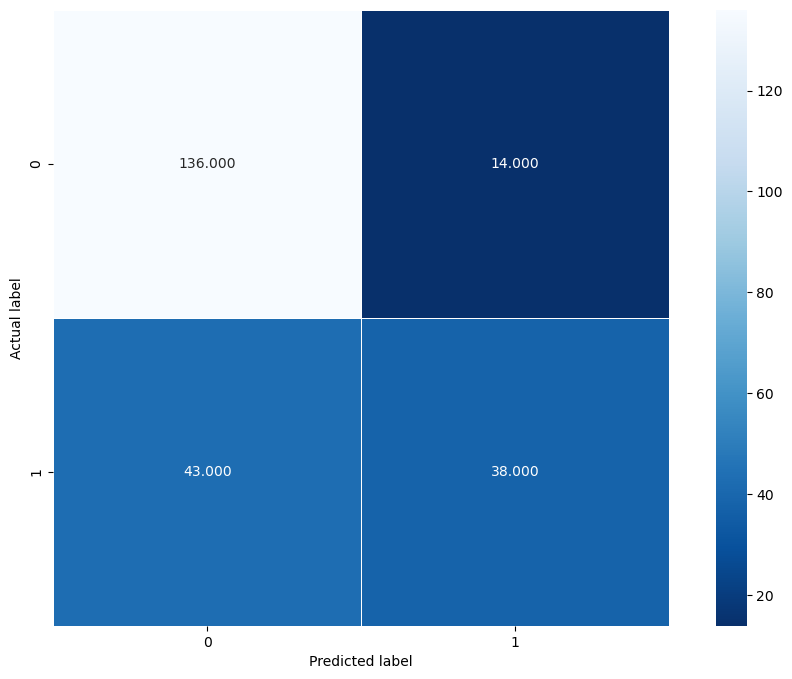

In [12]:
cm = metrics.confusion_matrix(y_test, mypred)
plt.figure(figsize=(12,8))
sns.heatmap(cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

## 4.5 Questions

##### Question 1: See section 4.3

##### Question 2: See section 4.3

##### Question 3: See section 4.3

##### Question 4: See section 4.4

##### Question 5: See section 4.4

##### Question 6: See section 4.4

##### Question 7: Play around with the different "solvers" (lbfgs, saga, newton-cg) and different levels of max_iteration. Which model results in the best accuracy?

In [33]:
solvers = ['liblinear', 'lbfgs', 'newton-cg', 'sag', 'saga']
itterbug = [10, 100, 1000, 10000, 100000]

for i in itterbug:
    for sol in solvers:
        logisticRegr = LogisticRegression(max_iter=i, solver=sol)
        logisticRegr.fit(X_train, y_train)

        AccScore = logisticRegr.score(X_test, y_test)

        print(AccScore, f"=> With solver {sol} and ItterMax {i}")
    

0.7489177489177489 => With solver liblinear and ItterMax 10
0.6493506493506493 => With solver lbfgs and ItterMax 10
0.7532467532467533 => With solver newton-cg and ItterMax 10
0.6493506493506493 => With solver sag and ItterMax 10
0.6493506493506493 => With solver saga and ItterMax 10
0.7489177489177489 => With solver liblinear and ItterMax 100
0.7532467532467533 => With solver lbfgs and ItterMax 100
0.7532467532467533 => With solver newton-cg and ItterMax 100
0.6493506493506493 => With solver sag and ItterMax 100
0.6493506493506493 => With solver saga and ItterMax 100
0.7489177489177489 => With solver liblinear and ItterMax 1000
0.7532467532467533 => With solver lbfgs and ItterMax 1000
0.7532467532467533 => With solver newton-cg and ItterMax 1000
0.7402597402597403 => With solver sag and ItterMax 1000
0.70995670995671 => With solver saga and ItterMax 1000
0.7489177489177489 => With solver liblinear and ItterMax 10000
0.7532467532467533 => With solver lbfgs and ItterMax 10000
0.75324675

Best accuracy for this model: 0.7532467532467533 => With solver lbfgs and ItterMax 10000

##### Question 8: Go back to the correlation matrix we drew in section 4.3. Figure out which other features might be useful when predicting diabetes. Retrain your model and calculate all metrics. Play around with other possible features and create some new ones to try the interaction effect. What is the best model you can achieve?

### Stats to beat:

Accuracy: 0.7532467532467533

Precision: 0.749605143459892

Specificity score: 0.6225557158890492

Recall score: 0.7532467532467533

F1 score: 0.7372202265819287

In [48]:
data = df[["Glucose", "BMI", "Age"]]
booldata = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(data, booldata, test_size=0.3, random_state=101)

NewModel1 = LogisticRegression(max_iter=10000)
NewModel1.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

### Newmodel 1

In [49]:
accuracy = NewModel1.score(X_test, y_test)
print("Accuracy:",accuracy)

mypred = NewModel1.predict(X_test)
Precision = precision_score(y_test, mypred, average="weighted")
print("Precision:",Precision)

SS = specificity_score(y_test, mypred, average="weighted")
print("Specificity score:",SS)

RecallScore = recall_score(y_test, mypred, average="weighted")
print("Recall score:",RecallScore)

F1score = f1_score(y_test, mypred, average="weighted")
print("F1 score:",F1score)

Accuracy: 0.7619047619047619
Precision: 0.7560015741833923
Specificity score: 0.6726631393298059
Recall score: 0.7619047619047619
F1 score: 0.7554259799157759


### Conclusion of newmodel 1:

The model barely improved across all statistics compared to the GlucoseModel. The improvement is there, though dissapointing. Other variables might yield better results

### Newmodel 2

In [4]:
data = df[["Glucose", "BMI", "DiabetesPedigreeFunction"]]
booldata = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(data, booldata, test_size=0.3, random_state=101)

NewModel2 = LogisticRegression(max_iter=10000)
NewModel2.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

In [5]:
accuracy = NewModel2.score(X_test, y_test)
print("Accuracy:",accuracy)

mypred = NewModel2.predict(X_test)
Precision = precision_score(y_test, mypred, average="weighted")
print("Precision:",Precision)

SS = specificity_score(y_test, mypred, average="weighted")
print("Specificity score:",SS)

RecallScore = recall_score(y_test, mypred, average="weighted")
print("Recall score:",RecallScore)

F1score = f1_score(y_test, mypred, average="weighted")
print("F1 score:",F1score)

Accuracy: 0.8051948051948052
Precision: 0.8019656272994418
Specificity score: 0.7301138367805035
Recall score: 0.8051948051948052
F1 score: 0.800742067290087


### Evaluation of newmodel 2

The improvements made by newmodel 2 are considerably higher than newmodel 1. Compared to the original glucose model:

Accuracy	+6.89%

Precision	+6.99%

Specificity	+17.29%

Recall	+6.89%

F1 Score	+8.62%

These improvement put newmodel 2 head and shoulders above GlucoseModel and newmodel 1

##### Question 9: Consider the person with values as described below. Using only the features you're using in your best model, does this person have diabetes or not?

| Pregnancies | Glucose | BloodPressure | SkinThickness | Insulin | BMI | DiabetesPedigreeFunction | Age |
| --- | --- |--- |--- |--- |--- |--- |--- |
| 8 | 190 | 92 | 41 | 33.6 | 39.3 | 0.278 | 52 |

In [7]:
Model2_Preds = NewModel2.predict([[190, 39.3, 0.278]])
if Model2_Preds[0] == 1:
    print("Diabetes detected!")
else:
    print("No diabetes detected")

Diabetes detected!
